### Import necessary packages

In [1]:
import muspan as ms
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt 
import os
import json

### Define pathways to be used

In [ ]:
domain_directory = r".\Template_Generated-Domains"


saving_neighbourhood_domain_directory = r".\Template_Domains-with-Neighbourhoods"
saving_matrix_directory = r".\Template_Neighbourhood-matrix"

if not os.path.exists(saving_neighbourhood_domain_directory):
    os.makedirs(saving_neighbourhood_domain_directory)

if not os.path.exists(saving_matrix_directory):
    os.makedirs(saving_matrix_directory)

### Load saved domains

In [3]:
saved_domains = os.listdir(domain_directory)

domains = []

for s_domain in saved_domains:
    domain = ms.io.load_domain(os.path.join(domain_directory,s_domain))
    domains.append(domain)

MuSpAn domain loaded successfully. Domain summary:
Domain name: test_data_1.csv
Number of objects: 102475
Collections: ['Cell centres']
Labels: ['Phenotype', 'ROI', 'CD8 intensity', 'PDPN intensity', 'aSMA intensity', 'PDGFRa intensity', 'FAP intensity', 'panCK intensity'] 
Networks: [] 
Distance matrices: []
MuSpAn domain loaded successfully. Domain summary:
Domain name: test_data_2.csv
Number of objects: 415261
Collections: ['Cell centres']
Labels: ['Phenotype', 'ROI', 'CD8 intensity', 'PDPN intensity', 'aSMA intensity', 'PDGFRa intensity', 'FAP intensity', 'panCK intensity'] 
Networks: [] 
Distance matrices: []
MuSpAn domain loaded successfully. Domain summary:
Domain name: test_data_3.csv
Number of objects: 229275
Collections: ['Cell centres']
Labels: ['Phenotype', 'ROI', 'CD8 intensity', 'PDPN intensity', 'aSMA intensity', 'PDGFRa intensity', 'FAP intensity', 'panCK intensity'] 
Networks: [] 
Distance matrices: []


### Create new neighbourhood matrices

In [4]:
# To force MuSpAn to use all classifications in the domains and not the common once, add all relevant markers here
phenotype_list = ['CD8', 'CD8_Other', 'FAP', 'FAP_PDGFRa', 'FAP_PDGFRa_aSMA', 'FAP_PDPN',
                   'FAP_PDPN_PDGFRa', 'FAP_PDPN_PDGFRa_aSMA', 'FAP_PDPN_aSMA', 'FAP_PDPN_panCK',
                    'FAP_aSMA', 'FAP_panCK', 'Other', 'PDGFRa', 'PDGFRa_aSMA', 'PDPN', 'PDPN_CD8',
                    'PDPN_CD8_Other', 'PDPN_PDGFRa', 'PDPN_PDGFRa_aSMA', 'PDPN_aSMA',
                    'PDPN_panCK', 'PDPN_panCK_Other', 'aSMA', 'panCK', 'panCK_Other', 'unclassified detections']

# A list of all markers can also be found by choosing a domain and getting all categories for a label type. 
# NOTE: all classifications might not exist in that chosen domain 
# classes = domains[0].labels["Phenotype"]["categories"]

In [5]:
# Perform KNN Neighbourhood Clustering on the list of domains

# More parameters can be varied, but these are some easy starting points
label_name = "Phenotype"

max_edge_distance = np.inf
n_clusters = 10


neighbourhood_enrichment_matrix, consistent_global_labels, unique_cluster_labels = ms.networks.cluster_neighbourhoods(
    domains,  # The domain dataset
    label_name='Phenotype',  # The label to use for clustering
    network_kwargs=dict(network_type='KNN', max_edge_distance=max_edge_distance, min_edge_distance=0, number_of_nearest_neighbours=10),  # The network parameters
    k_hops=1,  # The number of hops to consider for the neighbourhood
    neighbourhood_label_name='Neighbourhood ID - KNN '+str(n_clusters),  # Name for the neighbourhood label
    cluster_method='minibatchkmeans',  # Clustering method
    cluster_parameters={'n_clusters': n_clusters},  # Parameters for the clustering method
    neighbourhood_enrichment_as='zscore' # Neighbourhood enrichment as log-fold
)

var_dict = {"neighbourhood_enrichment_matrix":neighbourhood_enrichment_matrix.tolist(),
            "consistent_global_labels": consistent_global_labels,
            "unique_cluster_labels":unique_cluster_labels.tolist()}

saved_matrices_source_path = saving_matrix_directory
knn_path = 'matrix_knn'+str(n_clusters)

matrices_path = os.path.join(saved_matrices_source_path, knn_path)

with open(matrices_path, "w+") as f:
    json.dump(var_dict, f)
    
for domain in domains:
    ms.io.save_domain(domain, path_to_save=saving_neighbourhood_domain_directory, name_of_file= str(domain.name))

Domain test_data_1.csv saved successfully to .\Template_Domains-with_Neighbourhoods.
Domain test_data_2.csv saved successfully to .\Template_Domains-with_Neighbourhoods.
Domain test_data_3.csv saved successfully to .\Template_Domains-with_Neighbourhoods.


### Load in saved neighbourhood matrices

In [6]:
saved_matrices_source_path = saving_matrix_directory
knn_path = 'matrix_knn'+str(n_clusters)

matrices_path = os.path.join(saved_matrices_source_path, knn_path)

if os.path.isfile(matrices_path):
    with open(matrices_path, "r+") as f:
        matrices = json.load(f)

    
    neighbourhood_enrichment_matrix = np.array(matrices["neighbourhood_enrichment_matrix"])
    consistent_global_labels = matrices["consistent_global_labels"]
    unique_cluster_labels = np.array(matrices["unique_cluster_labels"])

### Print clustermap

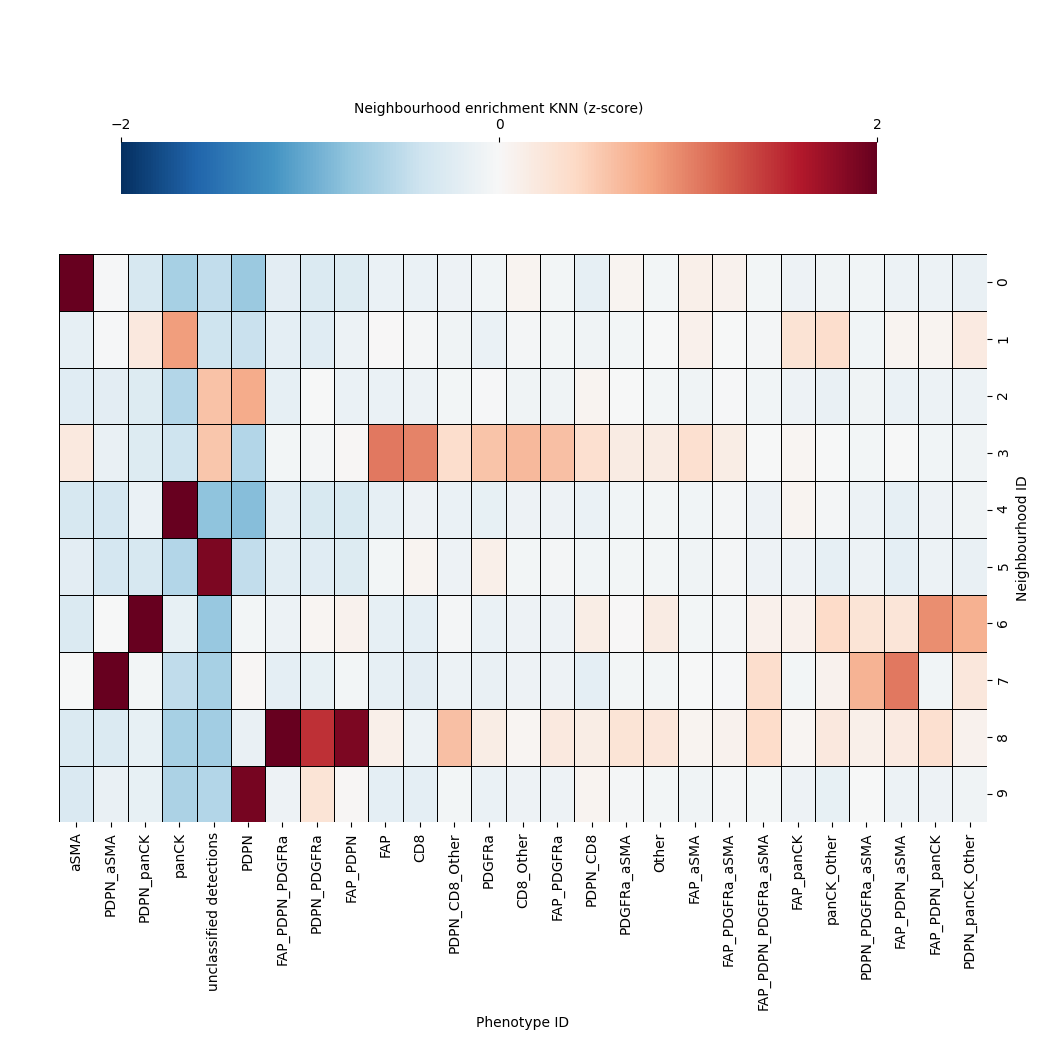

In [7]:
# Create a DataFrame from the neighbourhood enrichment matrix
df_ME_id = pd.DataFrame(data=neighbourhood_enrichment_matrix, index=unique_cluster_labels, columns=consistent_global_labels)
df_ME_id.index.name = 'Neighbourhood ID'
df_ME_id.columns.name = 'Phenotype ID'

# Visualize the neighbourhood enrichment matrix using a clustermap
sns.clustermap(
    df_ME_id,
    xticklabels=consistent_global_labels,
    yticklabels=unique_cluster_labels,
    figsize=(10.5, 10.5),
    cmap='RdBu_r',
    dendrogram_ratio=(.05, .3),
    col_cluster=True,
    row_cluster=False,
    square=True,
    linewidths=0.5,
    linecolor='black',
    cbar_kws=dict(use_gridspec=False, location="top", label='Neighbourhood enrichment KNN (z-score)', ticks=[-2, 0, 2]),
    cbar_pos=(0.12, 0.81, 0.72, 0.05), #left, bottom, width, height
    vmin=-2,
    vmax=2,
    tree_kws={'linewidths': 0, 'color': 'white'}
)

### Optional - Update colours of neighbourhoods

In [9]:
# Choose colours from https://matplotlib.org/3.1.1/gallery/color/named_colors.html

# Create a dictionary with the label category as key and the desired colour as value

neighbourhood_colours = {0:"maroon", 1:"lightsalmon", 2:"tan", 3:"gold", 4:"olivedrab", 
                         5:"lightgreen", 6:"cadetblue", 7:"navy", 8:"darkviolet", 9:"pink"}

# Save domains with updated colours if desired

for domain in domains:
    domain.update_colors(new_colors=neighbourhood_colours, colors_to_update="labels", label_name='Neighbourhood ID - KNN '+str(n_clusters))
    ms.io.save_domain(domain, path_to_save=saving_neighbourhood_domain_directory, name_of_file= str(domain.name))


Domain test_data_1.csv saved successfully to .\Template_Domains-with_Neighbourhoods.
Domain test_data_2.csv saved successfully to .\Template_Domains-with_Neighbourhoods.
Domain test_data_3.csv saved successfully to .\Template_Domains-with_Neighbourhoods.


### Visualise the neighbourhoods within a domain

(<Figure size 800x500 with 2 Axes>, <Axes: >)

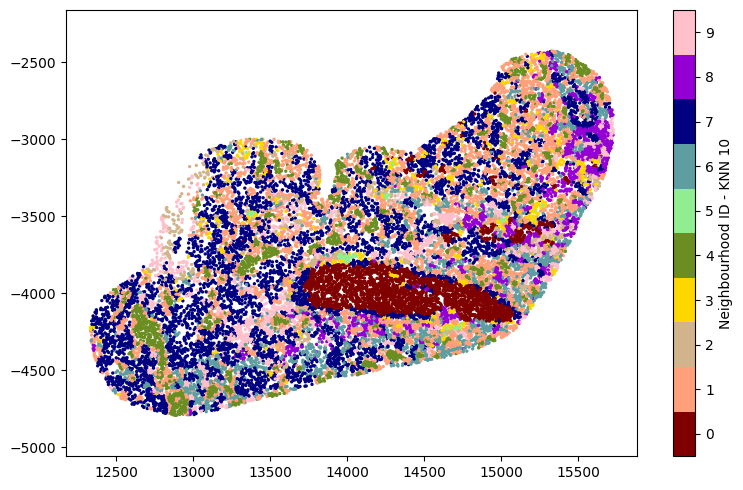

In [12]:
# Choose which domain to visualise
domain =  domains[1]

plt.figure(figsize=(8,5))

ms.visualise.visualise(domain, color_by="Neighbourhood ID - KNN "+str(n_clusters), 
                       ax=plt.gca(),  
                       marker_size= 2,
                       objects_to_plot=("ROI", "ROI 1"))